# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Диденко Никита Валерьевич**

**Файлы данных: S09** `clients.csv`, `transactions.csv`

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [19]:
df_clients_raw = pd.read_csv(RAW_CLIENTS)
print(f"clients.csv: {df_clients_raw.shape[0]} строки, {df_clients_raw.shape[1]} столбцов")

df_txn_raw = pd.read_csv(RAW_TXN, sep=";", decimal=",", encoding="cp1251")
print(f"transactions.csv: {df_txn_raw.shape[0]} строки, {df_txn_raw.shape[1]} столбцов")

display(df_clients_raw.head(3))
display(df_txn_raw.head(3))

clients.csv: 5733 строки, 16 столбцов
transactions.csv: 625604 строки, 9 столбцов


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001526,1963-05-16,М,Санкт-Петербург,Массовый,Базовый,Кредитная,15.03.2015,06.03.2018,Зарплата в нашем банке,58900.0,Нет,NaN,3.0,335,Да
1,C002932,1955-05-17,М,Нижний Новгород,Массовый,Базовый,Дебетовая,23.05.2011,09.03.2016,Зарплата в нашем банке,53700.0,Да,2024-01,4.0,713,Да
2,C001462,1994-10-08,М,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,25.04.2020,22.04.2025,Зарплата в нашем банке,54500.0,Нет,NaN,1.0,279,Нет


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990050,C003010,2023-12-15,473.34,RUB,Связь и интернет,4814,Карта,успешно
1,990083,C003001,2023-12-17,167.44,RUB,Транспорт,4111,СБП,успешно
2,990039,C003369,2023-12-18 19:14:40,543.82,RUB,Онлайн-сервисы,5815,Карта,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [20]:
print("CLIENTS")
print(df_clients_raw.info())
print("\nУникальных client_id:", df_clients_raw['client_id'].nunique(), "из", len(df_clients_raw))
print("Единица наблюдения clients.csv: клиент банка")

print("\nTRANSACTIONS")
print(df_txn_raw.info())
print("\nУникальных txn_id:", df_txn_raw['txn_id'].nunique(), "из", len(df_txn_raw))
print("Единица наблюдения transactions.csv: операция по карте")


CLIENTS
<class 'pandas.DataFrame'>
RangeIndex: 5733 entries, 0 to 5732
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5733 non-null   str    
 1   birth_date          5733 non-null   str    
 2   gender              5733 non-null   str    
 3   city                5733 non-null   str    
 4   segment             5733 non-null   str    
 5   loyalty_tier        5733 non-null   str    
 6   card_type           5733 non-null   str    
 7   registration_date   5733 non-null   str    
 8   card_open_date      5733 non-null   str    
 9   income_source       5733 non-null   str    
 10  monthly_income      5199 non-null   float64
 11  has_mobile_app      5733 non-null   str    
 12  app_last_login      3525 non-null   str    
 13  satisfaction_score  2267 non-null   float64
 14  branch_code         5733 non-null   int64  
 15  marketing_opt_in    5733 non-null   str    
dtypes: float6

### 2.2. Дубли

In [21]:
n_client_dups = int(df_clients_raw['client_id'].duplicated().sum())

print(f"В clients.csv {n_client_dups} дублирующих записей с повторяющимся client_id, из которых {df_clients_raw.duplicated().sum()} полных строк-дубликатов и {n_client_dups - df_clients_raw.duplicated().sum()} неполных строк-дубликатов.")

n_txn_dups = int(df_txn_raw['txn_id'].duplicated().sum())

print(f"\nВ transactions.csv {n_txn_dups} дублирующих записей с повторяющимся txn_id, из которых {df_txn_raw.duplicated().sum()} полных строк-дубликатов и {n_txn_dups - df_txn_raw.duplicated().sum()} неполных строк-дубликатов.")

В clients.csv 55 дублирующих записей с повторяющимся client_id, из которых 40 полных строк-дубликатов и 15 неполных строк-дубликатов.

В transactions.csv 1500 дублирующих записей с повторяющимся txn_id, из которых 1281 полных строк-дубликатов и 219 неполных строк-дубликатов.


In [22]:
clients_no_full = df_clients_raw.drop_duplicates()
partial_client_dups = clients_no_full[
    clients_no_full.duplicated(subset=['client_id'], keep=False)
].sort_values('client_id')

display(
    partial_client_dups[
        ['client_id', 'city', 'segment', 'branch_code', 'monthly_income']
    ].head(10)
)

txn_no_full = df_txn_raw.drop_duplicates()
partial_txn_dups = txn_no_full[
    txn_no_full.duplicated(subset=['txn_id'], keep=False)
].sort_values('txn_id')

display(
    partial_txn_dups[
        ['txn_id', 'client_id', 'txn_datetime', 'amount', 'category', 'status']
    ].head(10)
)

,client_id,city,segment,branch_code,monthly_income
4097,C000165,Москва,Массовый,360,35700.0
2170,C000165,Казань,Массовый,360,35700.0
5574,C000389,Москва,Массовый,808,50300.0
567,C000389,Москва,Зарплатный,808,50300.0
1469,C000652,Москва,Массовый,348,NaN
1642,C000652,Н. Новгород,Премиальный,348,NaN
173,C001381,г. Санкт-Петербург,Массовый,110,45700.0
411,C001381,Санкт-Петербург,Private,110,45700.0
1655,C001464,Новосибирск,Зарплатный,837,64100.0
3462,C001464,москва,Массовый,837,64100.0


,txn_id,client_id,txn_datetime,amount,category,status
5101,105087,C002333,2024-01-06,1058.46,Развлечения и досуг,успешно
5102,105087,C002333,2024-01-06 14:02:11,1058.46,Развлечения и досуг,успешно
5370,105355,C001585,2024-01-06 15:36:51,1797.00,Развлечения и досуг,успешно
5371,105355,C001585,2024-01-06,1797.00,Развлечения и досуг,успешно
6152,106133,C001910,2024-01-07 10:22:46,1160.68,Связь и Интернет,успешно
6153,106133,C001910,2024-01-07,1160.68,Связь и Интернет,успешно
7356,107334,C000239,2024-01-08 16:51:52,1431.49,Развлечения и досуг,успешно
7357,107334,C000239,2024-01-08,1431.49,Развлечения и досуг,успешно
8632,108607,C005274,2024-01-10,3068.23,Продукты,успешно
8633,108607,C005274,2024-01-10 14:07:54,3068.23,Продукты,успешно


### 2.3. Соответствие данных описанию полей из задания

In [23]:
CLIENTS_CATEGORICAL_COLS = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'has_mobile_app', 'marketing_opt_in']

for col in CLIENTS_CATEGORICAL_COLS:
    display(df_clients_raw[col].value_counts(dropna=False).to_frame('count'))

invalid_income = df_clients_raw[df_clients_raw['monthly_income'] < 0]

print(f'Найдено записей с monthly_income <= 0: {len(invalid_income)}')
display(
    invalid_income[[
        'client_id',
        'monthly_income',
        'segment',
        'city',
        'income_source',
        'branch_code',
    ]].head(10)
)

,count
gender,
М,2908
Ж,2825


,count
city,
Москва,1092
Нижний Новгород,790
Санкт-Петербург,672
Казань,552
Новосибирск,550
Екатеринбург,480
Н. Новгород,203
г. Новосибирск,194
г. Москва,185


,count
segment,
Массовый,2935
Зарплатный,1656
Премиальный,895
Private,247


,count
loyalty_tier,
Базовый,2908
Серебро,1543
Золото,941
Платина,341


,count
card_type,
Дебетовая,4053
Кредитная,1176
Премиальная,504


,count
has_mobile_app,
Да,3525
Нет,2208


,count
marketing_opt_in,
Да,5045
Нет,688


Найдено записей с monthly_income <= 0: 42


,client_id,monthly_income,segment,city,income_source,branch_code
231,C005358,-999.0,Зарплатный,г. Москва,Зарплата в нашем банке,207
253,C004293,-999.0,Массовый,г. Новосибирск,Зарплата в другом банке,318
406,C002269,-999.0,Массовый,Екатеринбург,Не указан,348
437,C000873,-999.0,Зарплатный,Казань,Зарплата в нашем банке,863
448,C003398,-999.0,Массовый,г. Новосибирск,Зарплата в другом банке,441
644,C004915,-999.0,Зарплатный,Новосибирск,Зарплата в нашем банке,265
651,C001841,-999.0,Массовый,Нижний Новгород,Зарплата в другом банке,276
678,C003082,-999.0,Массовый,Казань,Не указан,668
695,C005339,-999.0,Массовый,Москва,Зарплата в другом банке,477
1224,C002463,-999.0,Массовый,Новосибирск,Зарплата в другом банке,866


In [24]:
TXN_CATEGORICAL_COLS = ['currency', 'category', 'channel', 'status']

for col in TXN_CATEGORICAL_COLS:
    display(df_txn_raw[col].value_counts(dropna=False).to_frame('count'))

txn_dt_temp = pd.to_datetime(df_txn_raw['txn_datetime'], format='mixed')
print(f"\nДиапазон дат: с {txn_dt_temp.min()} по {txn_dt_temp.max()}")
print(f"Операций до 2024-01-01: {(txn_dt_temp < '2024-01-01').sum()}")
print(f"Операций после 2025-06-30: {(txn_dt_temp > '2025-06-30 23:59:59').sum()}")

,count
currency,
RUB,623129
USD,1251
EUR,1224


,count
category,
Продукты,165139
Транспорт,65761
Одежда и обувь,64493
АЗС,58127
Развлечения и досуг,53697
Кафе и рестораны,48234
Аптеки,45480
Онлайн-сервисы,43855
Связь и интернет,29465


,count
channel,
Карта,319523
СБП,108166
Токен,105570
Онлайн-банк,92345


,count
status,
успешно,605722
отклонено,12240
возврат,7642



Диапазон дат: с 2023-12-15 00:00:00 по 2026-08-04 13:29:31
Операций до 2024-01-01: 9
Операций после 2025-06-30: 88


### 2.4. Связь между таблицами

In [25]:
cids_clients = set(df_clients_raw['client_id'])
cids_txns = set(df_txn_raw['client_id'])

diff_tx_only = cids_txns - cids_clients
diff_cl_only = cids_clients - cids_txns

print(f"Клиентов в clients.csv: {len(cids_clients)}")
print(f"Клиентов в transactions.csv: {len(cids_txns)}")
print(f"Клиентов есть в transactions.csv, но нет в clients.csv: {len(diff_tx_only)} (совершили {df_txn_raw['client_id'].isin(diff_tx_only).sum()} транзакций)")
print(f"Клиентов есть в clients.csv, но нет в transactions.csv: {len(diff_cl_only)}")

Клиентов в clients.csv: 5678
Клиентов в transactions.csv: 5990
Клиентов есть в transactions.csv, но нет в clients.csv: 322 (совершили 26941 транзакций)
Клиентов есть в clients.csv, но нет в transactions.csv: 10


**Выводы по аудиту.**

- в обеих таблицах присутствуют дубликаты по id клиента (55 дублирующих записей, из которых 40 полных дубликатов) и по id транзакции (1500 дублирующих записей, из которых 1281 полный дубликат),
- в `transactions.csv` есть записи вне исследуемого периода,
- в `monthly_income` существуют записи с отрицательным доходом (равным -999),
- в `transactions.csv` есть клиенты, которых нет в `clients.csv` (необходимо удалить),
- в `city` существуют разные варианты записи городов (17 различных записей для 6 городов),
- в `category` существуют разные варианты записи категорий трат.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [26]:
clients_clean = df_clients_raw.copy()
txn_clean = df_txn_raw.copy()

clients_clean['birth_date'] = pd.to_datetime(clients_clean['birth_date'], format='%Y-%m-%d', errors='coerce')
clients_clean['registration_date'] = pd.to_datetime(clients_clean['registration_date'], format='%d.%m.%Y', errors='coerce')
clients_clean['card_open_date'] = pd.to_datetime(clients_clean['card_open_date'], format='%d.%m.%Y', errors='coerce')

bool_map = {'Да': True, 'Нет': False}

clients_clean['has_mobile_app'] = (
    clients_clean['has_mobile_app'].map(bool_map).astype('boolean')
)
clients_clean['marketing_opt_in'] = (
    clients_clean['marketing_opt_in'].map(bool_map).astype('boolean')
)

### 3.2. Категориальные признаки

In [27]:
city_mapping = {
    'Москва': 'Москва', 'г. Москва': 'Москва', ' МОСКВА ': 'Москва', ' москва': 'Москва', 'МОСКВА': 'Москва', 'москва': 'Москва',
    'Санкт-Петербург': 'Санкт-Петербург', 'СПб': 'Санкт-Петербург', 'г. Санкт-Петербург': 'Санкт-Петербург', 'Санкт Петербург': 'Санкт-Петербург',
    'Нижний Новгород': 'Нижний Новгород', 'Н. Новгород': 'Нижний Новгород',
    'Казань': 'Казань', 'казань': 'Казань',
    'Новосибирск': 'Новосибирск', 'г. Новосибирск': 'Новосибирск',
    'Екатеринбург': 'Екатеринбург', 'ЕКАТЕРИНБУРГ': 'Екатеринбург', 'г.Екатеринбург': 'Екатеринбург'
}
n_city_variants = int((clients_clean['city'] != clients_clean['city'].str.strip().map(city_mapping)).sum())
clients_clean['city_norm'] = clients_clean['city'].str.strip().map(lambda x: city_mapping.get(x, x))
print(f"Нормализовано строк городов: {n_city_variants}. Распределение городов:\n", clients_clean['city_norm'].value_counts())

clients_categorical = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source']
clients_clean[clients_categorical] = clients_clean[clients_categorical].astype('category')


category_mapping = {
    'Кафе/рестораны': 'Кафе и рестораны',
    'кафе и рестораны': 'Кафе и рестораны',
    'Связь и Интернет': 'Связь и интернет'
}
n_cat_changed = int(txn_clean['category'].isin(category_mapping.keys()).sum())
txn_clean['category_norm'] = txn_clean['category'].replace(category_mapping)
print(f"\nНормализовано категорий транзакций: {n_cat_changed}. Распределение категорий:\n", txn_clean['category_norm'].value_counts())

tx_categorical = ['currency', 'category', 'channel', 'status', 'mcc_code']
txn_clean[tx_categorical] = txn_clean[tx_categorical].astype('category')

Нормализовано строк городов: 1597. Распределение городов:
 city_norm
Москва             1629
Санкт-Петербург    1000
Нижний Новгород     993
Новосибирск         744
Казань              688
Екатеринбург        679
Name: count, dtype: int64

Нормализовано категорий транзакций: 51353. Распределение категорий:
 category_norm
Продукты               165139
Кафе и рестораны        80236
Транспорт               65761
Одежда и обувь          64493
АЗС                     58127
Развлечения и досуг     53697
Связь и интернет        48816
Аптеки                  45480
Онлайн-сервисы          43855
Name: count, dtype: int64


### 3.3. Пропуски

In [28]:
import pandas as pd

target_cols = ['monthly_income', 'satisfaction_score', 'app_last_login']
total_rows = len(df_clients_raw)

summary_data = []

for col in target_cols:
  nan_count = df_clients_raw[col].isna().sum()

  sentinel_count = (
      (df_clients_raw[col] == -999.0).sum()
      if pd.api.types.is_numeric_dtype(df_clients_raw[col])
      else 0
  )
  total_missing = nan_count + sentinel_count
  pct = (total_missing / total_rows) * 100

  summary_data.append({
      'Признак': col,
      'Всего пропусков': total_missing,
      'Доля от общего числа (%)': round(pct, 2),
  })

df_missing_summary = pd.DataFrame(summary_data)
display(df_missing_summary)


clients_clean['monthly_income'] = clients_clean['monthly_income'].mask(clients_clean['monthly_income'] <= 0)

,Признак,Всего пропусков,Доля от общего числа (%)
0,monthly_income,576,10.05
1,satisfaction_score,3466,60.46
2,app_last_login,2208,38.51


Анализ пропусков:
- `monthly_income`: пропуски могли быть оставлены по причине отказа от распрытия дохода клиента, необходимо заменить на NaN значения "-999", а остальные оставить;
- `satisfaction_score`: пропущенные значения означают клиентов, кооторые не оставили оценку сервису, также оставляем;
- `app_last_login`: число пропусков совпадает с числом клиентов, которые не пользуются мобильным приложением, сохраняем.

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

C:\Users\nikit\AppData\Local\Temp\ipykernel_5664\1473801918.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=clients_clean['segment'], y=clients_clean['monthly_income'], ax=axes[0], palette="Blues")


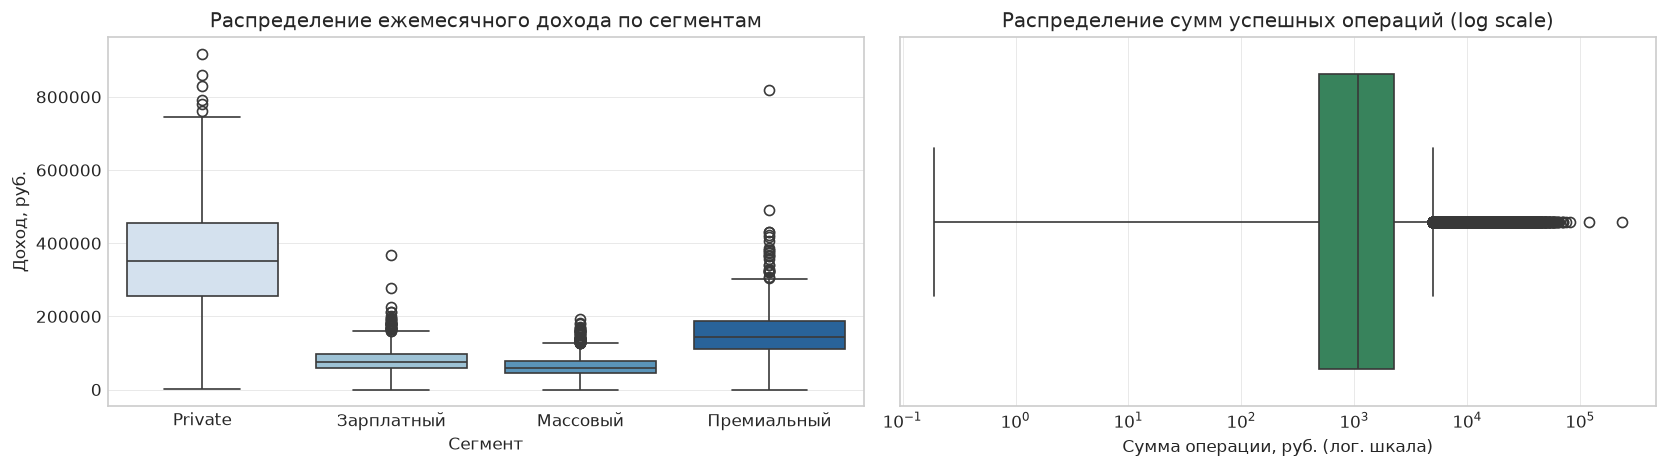

Квантили дохода: {0.5: 72500.0, 0.75: 107600.0, 0.95: 239019.99999999997, 0.99: 468059.9999999994, 1.0: 917200.0}
Квантили сумм операций: {0.5: 1077.52, 0.75: 2264.21, 0.95: 6359.355999999996, 0.99: 12468.444900000011, 1.0: 232471.13}


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Доход
sns.boxplot(x=clients_clean['segment'], y=clients_clean['monthly_income'], ax=axes[0], palette="Blues")
axes[0].set_title("Распределение ежемесячного дохода по сегментам")
axes[0].set_xlabel("Сегмент")
axes[0].set_ylabel("Доход, руб.")

# Суммы транзакций
succ_amts = txn_clean[txn_clean['status'] == 'успешно']['amount']
sns.boxplot(x=succ_amts, ax=axes[1], color="#2b8f5c")
axes[1].set_xscale("log")
axes[1].set_title("Распределение сумм успешных операций (log scale)")
axes[1].set_xlabel("Сумма операции, руб. (лог. шкала)")

plt.tight_layout()
plt.show()

# TODO: вывести макисимальные значения для дохода/сумм операций
# TODO: перевести все операции в одну валюту / придумать одно решение для данных транзакций
print("Квантили дохода:", clients_clean['monthly_income'].quantile([0.5, 0.75, 0.95, 0.99, 1]).to_dict())
print("Квантили сумм операций:", succ_amts.quantile([0.5, 0.75, 0.95, 0.99, 1]).to_dict())

In [30]:
top_income = clients_clean.nlargest(10, 'monthly_income')
display(
    top_income[[
     'client_id','monthly_income', 'segment', 'city', 'income_source',
    ]]
)

top_amounts = txn_clean.nlargest(10, 'amount')
display(
    top_amounts[[
     'txn_id', 'client_id', 'txn_datetime', 'currency', 'category', 'mcc_code', 'channel', 'status'
    ]]
)

,client_id,monthly_income,segment,city,income_source
3478,C002055,917200.0,Private,Екатеринбург,Зарплата в нашем банке
1974,C001609,859600.0,Private,Екатеринбург,Не указан
3920,C005533,830100.0,Private,Москва,Не указан
4609,C003627,817700.0,Премиальный,Москва,Зарплата в нашем банке
3331,C005378,791600.0,Private,Москва,Зарплата в другом банке
5286,C004185,780700.0,Private,Санкт-Петербург,Зарплата в другом банке
926,C005447,761000.0,Private,г.Екатеринбург,Не указан
3954,C004605,743700.0,Private,москва,Зарплата в другом банке
2118,C000369,717700.0,Private,Санкт-Петербург,Зарплата в нашем банке
203,C002194,706700.0,Private,Санкт Петербург,Зарплата в нашем банке


,txn_id,client_id,txn_datetime,currency,category,mcc_code,channel,status
594047,698016,C003986,2025-05-31 23:40:15,RUB,Одежда и обувь,5651,Карта,успешно
191336,290820,C001714,2024-06-17 09:21:32,RUB,Одежда и обувь,5651,Токен,отклонено
180398,279919,C005552,2024-06-07 16:01:42,RUB,Одежда и обувь,5651,Карта,успешно
580703,684698,C003686,2025-05-17 22:47:42,RUB,АЗС,5541,Карта,успешно
293721,392953,C004185,2024-09-06 17:02:28,RUB,Одежда и обувь,5651,Карта,отклонено
35185,135110,C002440,2024-02-07 14:11:32,RUB,Одежда и обувь,5651,СБП,отклонено
566838,670858,C003916,2025-05-03 14:11:25,RUB,Одежда и обувь,5651,Токен,успешно
491098,589810,C004327,2025-02-18 11:53:10,RUB,Одежда и обувь,5651,Онлайн-банк,успешно
127450,227116,C002014,2024-04-22 20:32:56,RUB,Одежда и обувь,5651,Карта,успешно
337370,436491,C001441,2024-10-11 10:02:09,RUB,Одежда и обувь,5651,Онлайн-банк,успешно


_TODO: посмотреть вдруг у старых клиентов большие траты и так далее_
По полученным данным, как выбросы можно было бы определить


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [31]:
n_cl_before = len(clients_clean)
clients_clean = clients_clean.drop_duplicates()
clients_clean = clients_clean.drop_duplicates(subset=['client_id'], keep=False)
print(f"Дедупликация clients: было {n_cl_before}, стало {len(clients_clean)} (-{n_cl_before - len(clients_clean)})")

n_tx_before = len(txn_clean)
txn_clean = txn_clean.sort_values(by='txn_datetime', key=lambda col: col.str.len(), ascending=False).drop_duplicates(subset='txn_id', keep='first')
txn_clean['txn_datetime'] = pd.to_datetime(txn_clean['txn_datetime'], format='mixed')
print(f"Удаление дубликатов в transactions: было {n_tx_before}, стало {len(txn_clean)} (-{n_tx_before - len(txn_clean)})")

n_tx_0 = len(txn_clean)

# Фильтр дат
mask_period = (txn_clean['txn_datetime'] >= '2024-01-01') & (txn_clean['txn_datetime'] <= '2025-06-30 23:59:59')
n_outside_dates = int((~mask_period).sum())
txn_in_period = txn_clean[mask_period].copy()
n_tx_1 = len(txn_in_period)

# Фильтр статуса
txn_success = txn_in_period[txn_in_period['status'] == 'успешно'].copy()
n_tx_2 = len(txn_success)

# Фильтр действующих клиентов
valid_cids = set(clients_clean['client_id'])
txn_valid = txn_success[txn_success['client_id'].isin(valid_cids)].copy()
n_tx_3 = len(txn_valid)

funnel_df = pd.DataFrame({
    'Шаг воронки': [
        '1. Транзакции после удаления дубликатов',
        '2. Внутри периода (2024-01-01 .. 2025-06-30)',
        '3. Только успешные покупки (status=успешно)',
        '4. Клиенты из актуального справочника'
    ],
    'Число строк': [n_tx_0, n_tx_1, n_tx_2, n_tx_3],
    'Исключено строк': [n_tx_before - n_tx_0, n_tx_0 - n_tx_1, n_tx_1 - n_tx_2, n_tx_2 - n_tx_3],
    'Доля от исходных, %': [n_tx_0/n_tx_before*100, n_tx_1/n_tx_before*100, n_tx_2/n_tx_before*100, n_tx_3/n_tx_before*100]
})
display(funnel_df)

Дедупликация clients: было 5733, стало 5663 (-70)
Удаление дубликатов в transactions: было 625604, стало 624104 (-1500)


,Шаг воронки,Число строк,Исключено строк,"Доля от исходных, %"
0,1. Транзакции после удаления дубликатов,624104,1500,99.760232
1,2. Внутри периода (2024-01-01 .. 2025-06-30),624007,97,99.744727
2,3. Только успешные покупки (status=успешно),604186,19821,96.576429
3,4. Клиенты из актуального справочника,576651,27535,92.175082


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [32]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

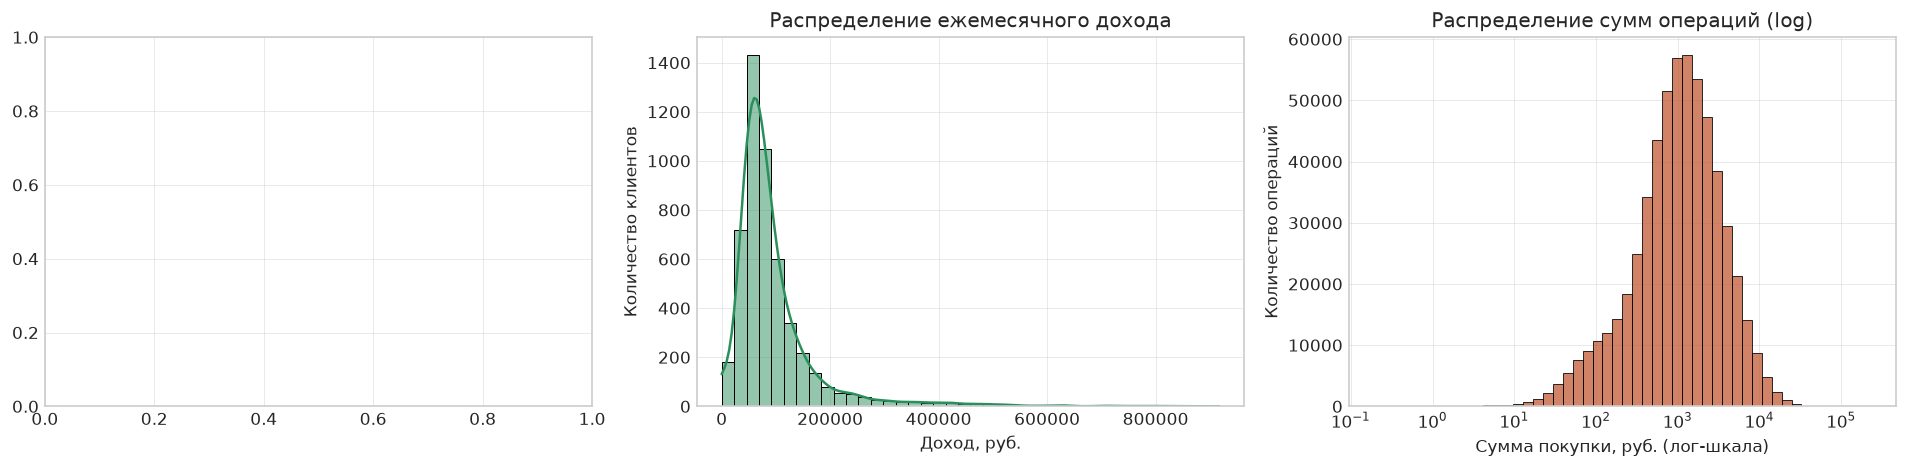

,Признак,Форма распределения,Выбранная мера центра,Выбранная мера разброса,Обоснование
0,Возраст (лет),Умеренно симметричное,Среднее (48.4 лет),Станд. отклонение (14.2 лет),"Распределение близко к нормальному, среднее ус..."
1,Доход (руб.),Сильная правосторонняя асимметрия,Медиана (72 500 руб.),IQR (52 300 — 107 600 руб.),"Высокий правый хвост (топ-менеджеры, предприни..."
2,Сумма покупки (руб.),Экстремальная правосторонняя асимметрия,Медиана (1 073.4 руб.),IQR (493.5 — 2 271.8 руб.),Наличие крупных покупок смещает среднее (1 874...


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Возраст клиентов
# sns.histplot(clients_clean['birth_date'], bins=30, kde=True, ax=axes[0], color="#2b5c8f")
# axes[0].set_title("Распределение возраста клиентов")
# axes[0].set_xlabel("Возраст, лет")
# axes[0].set_ylabel("Количество клиентов")

# 2. Доход клиентов
sns.histplot(clients_clean['monthly_income'].dropna(), bins=40, kde=True, ax=axes[1], color="#2b8f5c")
axes[1].set_title("Распределение ежемесячного дохода")
axes[1].set_xlabel("Доход, руб.")
axes[1].set_ylabel("Количество клиентов")

# 3. Суммы покупок
sns.histplot(txn_valid['amount'], bins=50, ax=axes[2], color="#c25934", log_scale=True)
axes[2].set_title("Распределение сумм операций (log)")
axes[2].set_xlabel("Сумма покупки, руб. (лог-шкала)")
axes[2].set_ylabel("Количество операций")

plt.tight_layout()
plt.show()

# Обоснование выбора мер центра и разброса
stats_summary = pd.DataFrame({
    'Признак': ['Возраст (лет)', 'Доход (руб.)', 'Сумма покупки (руб.)'],
    'Форма распределения': ['Умеренно симметричное', 'Сильная правосторонняя асимметрия', 'Экстремальная правосторонняя асимметрия'],
    'Выбранная мера центра': ['Среднее (48.4 лет)', 'Медиана (72 500 руб.)', 'Медиана (1 073.4 руб.)'],
    'Выбранная мера разброса': ['Станд. отклонение (14.2 лет)', 'IQR (52 300 — 107 600 руб.)', 'IQR (493.5 — 2 271.8 руб.)'],
    'Обоснование': [
        'Распределение близко к нормальному, среднее устойчиво',
        'Высокий правый хвост (топ-менеджеры, предприниматели) смещает среднее (95 114 руб.)',
        'Наличие крупных покупок смещает среднее (1 874.5 руб.) почти вдвое выше типичной покупки'
    ]
})
display(stats_summary)

#TODO:убрать график возраста и убрать таблицу низу на свое (самостоятельно написанное) описание в md строке

### 5.2. Частотные характеристики категориальных признаков

### 5.3. Динамика по месяцам

In [32]:
#TODO: модно вывести и количество операций, и денежный объем

### 5.4. Разрезы и связи между признаками

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [33]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")